# Churn Risk and Retention Targeting for a Music-Streaming Subscription (KKBox)

**Business question.** A subscription company can only contact a limited number of customers. *Which customers are about to churn, and who is worth contacting first?*

**Data.** KKBox churn challenge (Kaggle): ~993K subscribers, 21.5M transactions, member details. "Churn" = no renewal within 30 days after the membership expires.



## 1. Setup

In [1]:
import os, sys, time, math, warnings, subprocess, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# install only what is missing (Colab already has most of these)
_pkgs = {"duckdb": "duckdb", "lifelines": "lifelines", "statsmodels": "statsmodels", "sklearn": "scikit-learn"}
_missing = [p for m, p in _pkgs.items() if importlib.util.find_spec(m) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 150)
plt.rcParams["figure.figsize"] = (8, 4.5)

# ---------------- settings ----------------
DATA_DIR   = os.environ.get("KKBOX_DATA_DIR", "/content/data")     # folder with the four Kaggle CSVs
WORK_DIR   = os.environ.get("KKBOX_WORK_DIR", ".")                 # sql/, exports and the database file go here
DB_PATH    = os.path.join(WORK_DIR, "kkbox.duckdb")
SQL_DIR    = os.path.join(WORK_DIR, "sql")
EXPORT_DIR = os.path.join(WORK_DIR, "dashboard_exports")
os.makedirs(SQL_DIR, exist_ok=True); os.makedirs(EXPORT_DIR, exist_ok=True)

FEATURE_CUTOFF    = "2017-02-28"   # features use data up to this date only
RESOLUTION_CUTOFF = "2017-03-31"   # last date of data we can use to see who renewed
CHURN_WINDOW_DAYS = 30             # KKBox rule: churn = no renewal within 30 days after expiry
RANDOM_SEED = 42
COHORT_SAMPLE_PCT = int(os.environ.get("COHORT_SAMPLE_PCT", 100))   # lower (e.g. 10) for a quick trial run
np.random.seed(RANDOM_SEED)
print("data:", DATA_DIR, "| cutoff:", FEATURE_CUTOFF)

data: /content/data | cutoff: 2017-02-28


In [2]:
# Download from Kaggle only if the files are not already there
from pathlib import Path
REQUIRED = ["train.csv", "transactions.csv", "transactions_v2.csv", "members_v3.csv"]
def _have_all(): return all((Path(DATA_DIR) / f).exists() for f in REQUIRED)

if not _have_all():
    from getpass import getpass
    import shutil
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "py7zr", "--upgrade", "kaggle"], check=True)
    import py7zr
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    tok_path = os.path.expanduser("~/.kaggle/access_token")
    with open(tok_path, "w") as f: f.write(getpass("Kaggle API key: "))
    os.chmod(tok_path, 0o600); os.makedirs(DATA_DIR, exist_ok=True)
    for f in REQUIRED:
        subprocess.run(["kaggle", "competitions", "download", "-c", "kkbox-churn-prediction-challenge", "-f", f + ".7z", "-p", DATA_DIR], check=True)
        with py7zr.SevenZipFile(Path(DATA_DIR) / (f + ".7z"), mode="r") as z: z.extractall(path=DATA_DIR)
    for f in REQUIRED:                       # transactions_v2.csv sometimes lands in a sub-folder
        if not (Path(DATA_DIR) / f).exists():
            hits = sorted(Path(DATA_DIR).rglob(f), key=lambda p: len(str(p)))
            if hits: shutil.copy2(hits[0], Path(DATA_DIR) / f)
assert _have_all(), "input files missing"
for f in REQUIRED: print(f"{f:22s}{(Path(DATA_DIR)/f).stat().st_size/2**20:9.1f} MB")

Kaggle API key: ··········
train.csv                  44.5 MB
transactions.csv         1649.2 MB
transactions_v2.csv       110.0 MB
members_v3.csv            408.1 MB


## 2. SQL pipeline (DuckDB)

DuckDB runs inside the notebook and reads the big CSV files directly, so no database server is needed.
```
raw tables → cleaned tables → labels → features → one modelling table
```

In [3]:
import duckdb
con = duckdb.connect(DB_PATH)
con.execute("PRAGMA memory_limit='6GB'")
con.execute(f"PRAGMA temp_directory='{os.path.join(WORK_DIR, 'duck_tmp')}'")

# values that the .sql files use as {{PLACEHOLDERS}}
PARAMS = {"DATA_DIR": DATA_DIR, "FEATURE_CUTOFF": FEATURE_CUTOFF, "RESOLUTION_CUTOFF": RESOLUTION_CUTOFF,
          "CHURN_WINDOW_DAYS": str(CHURN_WINDOW_DAYS),
          "LABEL_RENEWED": "renewed_extend",   # which renewal rule defines the label (explained in Section 3)
          "CANCEL_AWARE": "1"}                 # 1 = respect cancellation rows when finding the expiry date (Section 3)

def run_sql(name, show=False):
    text = open(os.path.join(SQL_DIR, f"{name}.sql")).read()
    for k, v in PARAMS.items(): text = text.replace("{{" + k + "}}", v)
    t0 = time.time(); res = con.execute(text)
    print(f"[{name}] {time.time()-t0:.0f}s"); return res.df() if show else None

**Step 1: load the raw files**

In [4]:
%%writefile sql/01_load.sql
-- 01_load.sql : raw CSVs -> DuckDB tables (dates parsed from YYYYMMDD integers)
CREATE OR REPLACE TABLE raw_train AS
SELECT * FROM read_csv_auto('{{DATA_DIR}}/train.csv');

CREATE OR REPLACE TABLE raw_members AS
SELECT * FROM read_csv('{{DATA_DIR}}/members_v3.csv',
    types = {'registration_init_time': 'DATE'}, dateformat = '%Y%m%d');

CREATE OR REPLACE TABLE raw_txn AS
SELECT * FROM read_csv('{{DATA_DIR}}/transactions.csv',
    types = {'transaction_date': 'DATE', 'membership_expire_date': 'DATE'},
    dateformat = '%Y%m%d');

CREATE OR REPLACE TABLE raw_txn_v2 AS
SELECT * FROM read_csv('{{DATA_DIR}}/transactions_v2.csv',
    types = {'transaction_date': 'DATE', 'membership_expire_date': 'DATE'},
    dateformat = '%Y%m%d');

Writing sql/01_load.sql


In [5]:
run_sql("01_load")
if COHORT_SAMPLE_PCT < 100:   # optional shortcut for a quick trial run
    con.execute(f"CREATE OR REPLACE TABLE raw_train AS SELECT * FROM raw_train USING SAMPLE {COHORT_SAMPLE_PCT} PERCENT (bernoulli, {RANDOM_SEED})")
print(con.sql("SELECT (SELECT COUNT(*) FROM raw_train) AS customers, (SELECT COUNT(*) FROM raw_members) AS members, "
              "(SELECT COUNT(*) FROM raw_txn) AS transactions_to_feb, (SELECT COUNT(*) FROM raw_txn_v2) AS transactions_march").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[01_load] 44s
   customers  members  transactions_to_feb  transactions_march
0     992931  6769473             21547746             1431009


**Step 2: data-quality audit on the full tables**

In [6]:
%%writefile sql/02_quality_checks.sql
-- 02_quality_checks.sql : null audits, outlier ages, invalid expiry-before-transaction dates, orphan keys
SELECT 'transactions rows (v1)' AS check_name, COUNT(*) AS n FROM raw_txn
UNION ALL SELECT 'transactions rows (v2)', COUNT(*) FROM raw_txn_v2
UNION ALL SELECT 'train cohort size', COUNT(*) FROM raw_train
UNION ALL SELECT 'expire date < transaction date',
       COUNT(*) FROM raw_txn WHERE membership_expire_date < transaction_date
UNION ALL SELECT 'expire date before 2000',
       COUNT(*) FROM raw_txn WHERE membership_expire_date < DATE '2000-01-01'
UNION ALL SELECT 'null expire / amount / plan days',
       COUNT(*) FROM raw_txn
       WHERE membership_expire_date IS NULL OR actual_amount_paid IS NULL OR payment_plan_days IS NULL
UNION ALL SELECT 'members: age outside 1-99',
       COUNT(*) FROM raw_members WHERE bd <= 0 OR bd >= 100
UNION ALL SELECT 'members: missing gender',
       COUNT(*) FROM raw_members WHERE gender IS NULL
UNION ALL SELECT 'members: duplicate msno',
       COUNT(*) - COUNT(DISTINCT msno) FROM raw_members
UNION ALL SELECT 'cohort customers with no transactions',
       COUNT(*) FROM raw_train t WHERE NOT EXISTS (SELECT 1 FROM raw_txn x WHERE x.msno = t.msno)
UNION ALL SELECT 'cohort customers missing from members',
       COUNT(*) FROM raw_train t WHERE NOT EXISTS (SELECT 1 FROM raw_members m WHERE m.msno = t.msno);

Writing sql/02_quality_checks.sql


In [7]:
qc = run_sql("02_quality_checks", show=True)
n_txn = int(qc.loc[qc.check_name == "transactions rows (v1)", "n"].iloc[0])
qc["pct_of_table"] = np.where(qc.check_name.isin(["expire date < transaction date", "expire date before 2000"]), (100 * qc.n / n_txn).round(3), np.nan)
display(qc); qc.to_csv(os.path.join(EXPORT_DIR, "data_quality_audit.csv"), index=False)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[02_quality_checks] 5s


,check_name,n,pct_of_table
0,transactions rows (v1),21547746,NaN
1,transactions rows (v2),1431009,NaN
2,train cohort size,992931,NaN
3,expire date < transaction date,153660,0.713
4,expire date before 2000,1778,0.008
5,null expire / amount / plan days,0,NaN
6,members: age outside 1-99,4546009,NaN
7,members: missing gender,4429505,NaN
8,members: duplicate msno,0,NaN
9,cohort customers with no transactions,0,NaN


**Step 3: clean the data.** Remove impossible rows (expiry date *before* the transaction date), keep only transactions up to the cutoff, and flag customers with an invalid age.

In [8]:
%%writefile sql/03_staging.sql
-- 03_staging.sql
CREATE OR REPLACE TABLE stg_txn AS
SELECT t.*
FROM raw_txn t
JOIN raw_train c USING (msno)
WHERE t.transaction_date <= DATE '{{FEATURE_CUTOFF}}'
  AND t.membership_expire_date IS NOT NULL
  AND t.membership_expire_date >= t.transaction_date;

CREATE OR REPLACE TABLE stg_members AS
SELECT m.msno,
       m.city,
       m.registered_via,
       m.registration_init_time,
       CASE WHEN m.bd BETWEEN 1 AND 99 THEN m.bd END  AS bd,
       (m.bd IS NULL OR m.bd NOT BETWEEN 1 AND 99)    AS age_missing,
       COALESCE(m.gender, 'unknown')                  AS gender
FROM raw_members m
JOIN raw_train c USING (msno)
QUALIFY ROW_NUMBER() OVER (PARTITION BY m.msno ORDER BY m.registration_init_time) = 1;

Writing sql/03_staging.sql


In [9]:
run_sql("03_staging")
print(con.sql("SELECT (SELECT COUNT(*) FROM stg_txn) AS clean_transactions, (SELECT COUNT(*) FROM stg_members) AS clean_members").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[03_staging] 15s
   clean_transactions  clean_members
0            15817793         877161


**Step 4: build the churn label.**


In [10]:
%%writefile sql/04_labels.sql
-- 04_labels.sql  (cancel-aware version)
-- CANCEL_AWARE = 1 : if a customer's most recent transaction is a cancellation, the membership ends at THAT row's expiry date
--                    (a cancel row can move the expiry EARLIER than the max over older rows)
-- CANCEL_AWARE = 0 : original rule (max expiry over all rows) -> reproduces v1 / the reconciliation numbers
CREATE OR REPLACE TABLE last_state AS
WITH ranked AS (
    SELECT msno, membership_expire_date, is_cancel,
           ROW_NUMBER() OVER (PARTITION BY msno ORDER BY transaction_date DESC, membership_expire_date DESC) AS rn,
           MAX(membership_expire_date) OVER (PARTITION BY msno)                                              AS max_expire
    FROM stg_txn
)
SELECT msno,
       CASE WHEN {{CANCEL_AWARE}} = 1 AND is_cancel = 1 THEN membership_expire_date ELSE max_expire END AS last_expire
FROM ranked
WHERE rn = 1;

CREATE OR REPLACE TABLE labels AS
WITH base AS (
    SELECT msno, last_expire, last_expire + {{CHURN_WINDOW_DAYS}} AS window_end
    FROM last_state
    WHERE last_expire + {{CHURN_WINDOW_DAYS}} > DATE '{{FEATURE_CUTOFF}}'
),
renew AS (
    SELECT b.msno,
           MAX(CASE WHEN v.transaction_date >  b.last_expire THEN 1 ELSE 0 END) AS renewed_strict,
           MAX(CASE WHEN v.transaction_date >= b.last_expire THEN 1 ELSE 0 END) AS renewed_sameday,
           MAX(CASE WHEN v.membership_expire_date > b.last_expire THEN 1 ELSE 0 END) AS renewed_extend
    FROM base b
    JOIN raw_txn_v2 v ON v.msno = b.msno
    WHERE v.transaction_date >  DATE '{{FEATURE_CUTOFF}}'
      AND v.transaction_date <= b.window_end
    GROUP BY b.msno
),
flagged AS (
    SELECT b.msno, b.last_expire, b.window_end,
           (b.window_end <= DATE '{{RESOLUTION_CUTOFF}}')  AS resolvable,
           COALESCE(r.renewed_strict, 0)                   AS renewed_strict,
           COALESCE(r.renewed_sameday, 0)                  AS renewed_sameday,
           COALESCE(r.renewed_extend, 0)                   AS renewed_extend
    FROM base b
    LEFT JOIN renew r USING (msno)
)
SELECT msno, last_expire, resolvable, renewed_strict, renewed_sameday, renewed_extend,
       CASE WHEN resolvable AND renewed_strict  = 0 THEN 1 ELSE 0 END AS event_strict,
       CASE WHEN resolvable AND renewed_sameday = 0 THEN 1 ELSE 0 END AS event_sameday,
       CASE WHEN resolvable AND renewed_extend  = 0 THEN 1 ELSE 0 END AS event_extend,
       CASE WHEN resolvable AND {{LABEL_RENEWED}} = 0 THEN 1 ELSE 0 END AS event,
       DATEDIFF('day', DATE '{{FEATURE_CUTOFF}}',
                CASE WHEN resolvable AND {{LABEL_RENEWED}} = 0 THEN window_end
                     ELSE DATE '{{RESOLUTION_CUTOFF}}' END)            AS duration
FROM flagged;

Writing sql/04_labels.sql


In [11]:
run_sql("04_labels")
print(con.sql("SELECT COUNT(*) AS customers, SUM(resolvable::INT) AS outcome_observable, SUM(event) AS churn_events FROM labels").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 16s
   customers  outcome_observable  churn_events
0     987567            121280.0       57981.0


**Step 5: build the features** (all from data up to 28 Feb)

In [12]:
%%writefile sql/05_features.sql
-- 05_features.sql : strictly pre-cutoff (stg_txn only contains transaction_date <= cutoff)
CREATE OR REPLACE TABLE txn_features AS
WITH ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY msno
                              ORDER BY transaction_date DESC, membership_expire_date DESC) AS rn
    FROM stg_txn
),
last_txn AS (
    SELECT msno,
           payment_method_id  AS last_payment_method,
           payment_plan_days  AS last_plan_days,
           is_auto_renew      AS last_auto_renew,
           is_cancel          AS last_is_cancel
    FROM ranked
    WHERE rn = 1
),
agg AS (
    SELECT msno,
           COUNT(*)                                            AS n_transactions,
           SUM(is_cancel)                                      AS n_cancels,
           AVG(is_auto_renew)                                  AS auto_renew_ratio,
           AVG(payment_plan_days)                              AS avg_plan_days,
           SUM(actual_amount_paid)                             AS total_amount_paid,
           SUM(payment_plan_days)                              AS total_plan_days,
           COALESCE(AVG(1 - actual_amount_paid / NULLIF(plan_list_price, 0)), 0) AS avg_discount_ratio,
           COUNT(DISTINCT payment_method_id)                   AS n_payment_methods,
           MIN(transaction_date)                               AS first_txn,
           MAX(transaction_date)                               AS last_txn_date,
           SUM(CASE WHEN transaction_date > DATE '{{FEATURE_CUTOFF}}' - 90 THEN 1 ELSE 0 END)         AS n_txn_last_90d,
           SUM(CASE WHEN transaction_date > DATE '{{FEATURE_CUTOFF}}' - 90 THEN is_cancel ELSE 0 END) AS n_cancel_last_90d
    FROM stg_txn
    GROUP BY msno
)
SELECT a.*,
       l.* EXCLUDE (msno),
       a.n_cancels * 1.0 / a.n_transactions                                    AS cancel_rate,
       DATEDIFF('day', a.last_txn_date, DATE '{{FEATURE_CUTOFF}}')             AS days_since_last_txn,
       a.total_amount_paid * 30.0 / GREATEST(a.total_plan_days, 30)            AS spend_per_30d
FROM agg a
JOIN last_txn l USING (msno);

Writing sql/05_features.sql


In [13]:
run_sql("05_features")
print(con.sql("SELECT COUNT(*) AS customers_with_features FROM txn_features").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[05_features] 25s
   customers_with_features
0                   992928


**Step 6: one modelling table**

In [14]:
%%writefile sql/06_model_table.sql
-- 06_model_table.sql
-- `resolvable` and `last_expire` are kept ONLY for diagnostics (censoring-bias check); they are never model inputs.
-- `event_strict/sameday/extend` are kept only for label-quality comparison.
-- `is_churn_official` (Kaggle's label) is an EVALUATION / CALIBRATION target only - never a feature.
CREATE OR REPLACE TABLE model_table AS
SELECT lb.msno, lb.duration, lb.event, lb.event_strict, lb.event_sameday, lb.event_extend, lb.resolvable, lb.last_expire,
       tr.is_churn AS is_churn_official,
       m.city, m.registered_via, m.gender, m.bd,
       COALESCE(m.age_missing, TRUE) AS age_missing,        -- customers absent from members_v3 -> age unknown
       DATEDIFF('day', COALESCE(m.registration_init_time, f.first_txn), DATE '{{FEATURE_CUTOFF}}') AS tenure_days,
       f.* EXCLUDE (msno, first_txn, last_txn_date, total_plan_days)
FROM labels lb
LEFT JOIN raw_train tr USING (msno)
LEFT JOIN stg_members m USING (msno)
LEFT JOIN txn_features f USING (msno);

Writing sql/06_model_table.sql


In [15]:
run_sql("06_model_table")

# ---------- safety checks ----------
latest = con.sql("SELECT MAX(transaction_date) FROM stg_txn").fetchone()[0]
assert str(latest) <= FEATURE_CUTOFF, f"features use data after the cutoff: {latest}"
assert con.sql("SELECT COUNT(*) - COUNT(DISTINCT msno) FROM model_table").fetchone()[0] == 0, "duplicate customers"
assert con.sql("SELECT COUNT(*) FROM model_table WHERE n_transactions IS NULL OR duration IS NULL").fetchone()[0] == 0, "unexpected NULLs"
print(f"OK: latest transaction used for features = {latest} (cutoff {FEATURE_CUTOFF}) | no duplicate customers | no NULLs in core columns")
print(con.sql("SELECT COUNT(*) AS customers FROM model_table").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 4s
OK: latest transaction used for features = 2017-02-28 (cutoff 2017-02-28) | no duplicate customers | no NULLs in core columns
   customers
0     987567


## 3. Is my churn label correct? (checking it against Kaggle's official flag)


In [16]:
def confusion_metrics(TP, FP, FN, TN):
    n = TP + FP + FN + TN
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
    po = (TP + TN) / n; pe = ((TP + FP) * (TP + FN) + (FN + TN) * (FP + TN)) / n**2
    return dict(precision=round(prec, 4), recall=round(rec, 4), F1=round(2 * prec * rec / max(prec + rec, 1e-12), 4), kappa=round((po - pe) / (1 - pe), 4))

def cohort_confusion(event_col):
    """Compare a label column with Kaggle's flag on the FULL cohort. Customers missing from model_table
    (already churned before the cutoff) count as predicted churn."""
    t = con.sql(f"""SELECT t.is_churn AS y, COALESCE(m.{event_col}, 1) AS pred, COUNT(*) AS n
                    FROM raw_train t LEFT JOIN model_table m USING (msno) GROUP BY 1, 2""").df()
    f = lambda y, p: int(t[(t.y == y) & (t.pred == p)].n.sum())
    return f(1, 1), f(0, 1), f(1, 0), f(0, 0)

BUCKET_SQL = f"""
SELECT CASE WHEN last_expire <= DATE '2017-03-01' THEN 'a: expires by 1 Mar (at risk)'
            WHEN last_expire <= DATE '2017-03-15' THEN 'b: 2-15 Mar' ELSE 'c: 16-31 Mar' END AS last_expire_bucket,
       last_is_cancel, COUNT(*) AS customers, ROUND(AVG(is_churn_official), 3) AS official_churn_rate
FROM model_table GROUP BY 1, 2 ORDER BY 1, 2"""

rows, buckets = [], {}
n_cohort = con.sql("SELECT COUNT(*) FROM raw_train").fetchone()[0]
for flag, expiry_name in [("0", "max expiry over all rows"), ("1", "cancel-aware (latest transaction)")]:
    PARAMS["CANCEL_AWARE"] = flag
    run_sql("04_labels"); run_sql("06_model_table")
    n_model = con.sql("SELECT COUNT(*) FROM model_table").fetchone()[0]
    for col, rule_name in [("event_strict", "strict (after expiry)"), ("event_sameday", "same-day (on/after expiry)"), ("event_extend", "membership extended")]:
        rows.append({"expiry rule": expiry_name, "renewal rule": rule_name, "customers set aside": n_cohort - n_model,
                     **confusion_metrics(*cohort_confusion(col))})
    buckets[expiry_name] = con.sql(BUCKET_SQL).df()
    if flag == "0":
        chk = con.sql("SELECT COUNT(*) AS rows, SUM(resolvable::INT) AS at_risk, SUM(event_strict) AS strict_events FROM labels").df().iloc[0]
        print("SQL (first rule) gives:", chk.to_dict(), "\nMy original pandas version gave: rows 992,928 | at risk 121,370 | strict events 74,396  (full data only)\n")

label_table = pd.DataFrame(rows); display(label_table)
label_table.to_csv(os.path.join(EXPORT_DIR, "label_quality.csv"), index=False)

PARAMS["CANCEL_AWARE"] = "1"                       # final choice
run_sql("04_labels"); run_sql("06_model_table")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 16s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 4s
SQL (first rule) gives: {'rows': 992928.0, 'at_risk': 121370.0, 'strict_events': 74396.0} 
My original pandas version gave: rows 992,928 | at risk 121,370 | strict events 74,396  (full data only)



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

,expiry rule,renewal rule,customers set aside,precision,recall,F1,kappa
0,max expiry over all rows,strict (after expiry),3,0.6311,0.7397,0.6811,0.6574
1,max expiry over all rows,same-day (on/after expiry),3,0.8096,0.7397,0.7731,0.7583
2,max expiry over all rows,membership extended,3,0.8090,0.7416,0.7738,0.7591
3,cancel-aware (latest transaction),strict (after expiry),5364,0.6532,0.8187,0.7266,0.7057
4,cancel-aware (latest transaction),same-day (on/after expiry),5364,0.8229,0.8187,0.8208,0.8086
5,cancel-aware (latest transaction),membership extended,5364,0.8222,0.8206,0.8214,0.8092


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 16s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 4s


In [17]:
for name, tb in buckets.items():
    print(f"--- expiry rule: {name} ---"); display(tb)
print("Customers whose last transaction is a cancel and whose max-expiry falls in March churn at ~80% (Kaggle's flag).")
print("The cancel-aware rule recognises that their membership really ended earlier.")

--- expiry rule: max expiry over all rows ---


,last_expire_bucket,last_is_cancel,customers,official_churn_rate
0,a: expires by 1 Mar (at risk),0,105207,0.308
1,a: expires by 1 Mar (at risk),1,16163,0.928
2,b: 2-15 Mar,0,388879,0.011
3,b: 2-15 Mar,1,5474,0.810
4,c: 16-31 Mar,0,474323,0.011
5,c: 16-31 Mar,1,2882,0.787


--- expiry rule: cancel-aware (latest transaction) ---


,last_expire_bucket,last_is_cancel,customers,official_churn_rate
0,a: expires by 1 Mar (at risk),0,105206,0.308
1,a: expires by 1 Mar (at risk),1,16074,0.911
2,b: 2-15 Mar,0,388879,0.011
3,b: 2-15 Mar,1,1846,0.531
4,c: 16-31 Mar,0,474323,0.011
5,c: 16-31 Mar,1,1239,0.605


Customers whose last transaction is a cancel and whose max-expiry falls in March churn at ~80% (Kaggle's flag).
The cancel-aware rule recognises that their membership really ended earlier.


In [18]:
first = label_table[(label_table["expiry rule"].str.startswith("max")) & (label_table["renewal rule"].str.startswith("strict"))].iloc[0]
chosen = label_table[(label_table["expiry rule"].str.startswith("cancel")) & (label_table["renewal rule"].str.startswith("membership"))].iloc[0]
top = label_table.sort_values("kappa", ascending=False).iloc[0]
print(f"Original rule : recall {first.recall}, precision {first.precision}, kappa {first.kappa}")
print(f"Chosen rule   : recall {chosen.recall}, precision {chosen.precision}, kappa {chosen.kappa}  (cancel-aware expiry + membership-extended renewal)")
print(f"Highest kappa in the table: {top['expiry rule']} + {top['renewal rule']} (kappa {top.kappa}). If a different rule scores clearly higher on your data (more than a few thousandths), look into why before continuing.")
print(f"Customers set aside (already churned before the cut-off, or no history): {int(chosen['customers set aside']):,}")

Original rule : recall 0.7397, precision 0.6311, kappa 0.6574
Chosen rule   : recall 0.8206, precision 0.8222, kappa 0.8092  (cancel-aware expiry + membership-extended renewal)
Highest kappa in the table: cancel-aware (latest transaction) + membership extended (kappa 0.8092). If a different rule scores clearly higher on your data (more than a few thousandths), look into why before continuing.
Customers set aside (already churned before the cut-off, or no history): 5,364


## 4. Who is actually at risk?


In [19]:
raw = con.sql("SELECT * FROM model_table").df()
raw["in_pool"] = raw["resolvable"].astype(bool)

facts = raw.groupby("in_pool").agg(customers=("msno", "size"), official_churners=("is_churn_official", "sum"),
                                   official_churn_rate=("is_churn_official", "mean"))
facts.index = facts.index.map({True: "at-risk pool", False: "everyone else"}); facts["share_of_customers"] = facts.customers / facts.customers.sum()
display(facts.round(4))
cover = facts.loc["at-risk pool", "official_churners"] / facts.official_churners.sum()
print(f"The pool is {facts.loc['at-risk pool','share_of_customers']:.1%} of customers but contains {cover:.1%} of all remaining churners.")
print(f"Overall churn rate is only {raw.is_churn_official.mean():.1%}, so 'accuracy' would be ~{1 - raw.is_churn_official.mean():.0%} even for a model that predicts nobody churns.")

,customers,official_churners,official_churn_rate,share_of_customers
in_pool,,,,
everyone else,866287,11114,0.0128,0.8772
at-risk pool,121281,47040,0.3879,0.1228


The pool is 12.3% of customers but contains 80.9% of all remaining churners.
Overall churn rate is only 5.9%, so 'accuracy' would be ~94% even for a model that predicts nobody churns.


In [20]:
cols = ["days_since_last_txn", "auto_renew_ratio", "last_auto_renew", "n_txn_last_90d", "n_transactions", "last_is_cancel", "last_plan_days", "tenure_days"]
a, b = raw[raw.in_pool], raw[~raw.in_pool]
smd = pd.DataFrame({"mean_pool": [a[c].astype(float).mean() for c in cols], "mean_rest": [b[c].astype(float).mean() for c in cols]}, index=cols)
smd["SMD"] = [(a[c].astype(float).mean() - b[c].astype(float).mean()) / math.sqrt((a[c].astype(float).var() + b[c].astype(float).var()) / 2) for c in cols]
display(smd.round(3))
print("The pool = lapsed customers (long since last transaction, auto-renew off, recent cancellations).")

,mean_pool,mean_rest,SMD
days_since_last_txn,70.316,14.327,0.776
auto_renew_ratio,0.595,0.915,-0.839
last_auto_renew,0.586,0.930,-0.876
n_txn_last_90d,1.917,2.875,-1.091
n_transactions,11.571,16.531,-0.604
last_is_cancel,0.133,0.004,0.530
last_plan_days,64.688,29.986,0.522
tenure_days,1109.410,1185.650,-0.073


The pool = lapsed customers (long since last transaction, auto-renew off, recent cancellations).


## 5. Preparing the at-risk pool for modelling

* **Target:** Kaggle's official churn flag (`is_churn_official`), the cleanest outcome available.
* **Missing members:** customers with no member record get `age_missing = 1`, gender "unknown", city "missing".
* **Rare categories** (under 1%) are pooled into "other".
* Skewed counts and amounts use `log1p`, then every numeric feature is standardized with **training-set** mean and SD, so a coefficient means "per +1 SD".
* **Split:** 75% train / 25% test, stratified on churn. The test set is used only for final reporting.

In [21]:
from sklearn.model_selection import train_test_split

P = raw[raw["in_pool"]].reset_index(drop=True).copy()

# DuckDB can return pandas "nullable" types; convert numeric ones to plain floats
for c in P.columns:
    if c in ("msno", "city", "registered_via", "last_payment_method"): continue
    if pd.api.types.is_extension_array_dtype(P[c].dtype) and (pd.api.types.is_numeric_dtype(P[c].dtype) or pd.api.types.is_bool_dtype(P[c].dtype)):
        P[c] = P[c].astype("float64")

n_no_member = int(P["city"].isna().sum())
P["age_missing"] = P["age_missing"].fillna(1).astype(int)
P["gender"] = P["gender"].fillna("unknown")
print(f"At-risk pool: {len(P):,} customers | {n_no_member:,} have no member record")

def _as_cat(v):
    if v is None or v is pd.NA or (isinstance(v, (float, np.floating)) and math.isnan(v)): return "missing"
    if isinstance(v, (float, np.floating)) and float(v).is_integer(): return str(int(v))
    return str(v)
def pool_rare(s, min_frac=0.01):
    s = s.astype("object").map(_as_cat); keep = s.value_counts(normalize=True)
    return s.where(s.isin(set(keep[keep >= min_frac].index)), "other")
for c in ["city", "registered_via", "last_payment_method"]: P[c] = pool_rare(P[c])

# group columns for the survival curves (built from the raw values, before any scaling)
P["spend_raw"] = P["spend_per_30d"].astype(float)
P["auto_renew_group"] = pd.cut(P.auto_renew_ratio, [-0.01, 0.33, 0.66, 1.0], labels=["low auto-renew", "medium auto-renew", "high auto-renew"]).astype(str)
P["plan_group"] = pd.cut(P.last_plan_days, [-1, 7, 30, 90, 10**6], labels=["<=7d plan", "8-30d plan", "31-90d plan", ">90d plan"]).astype(str)
P["payment_group"] = "pm_" + P.last_payment_method.where(P.last_payment_method.isin(P.last_payment_method.value_counts().index[:5]), "other")
P["tenure_group"] = pd.cut(P.tenure_days.clip(lower=0), [-1, 180, 365, 730, 10**7], labels=["<6 months", "6-12 months", "1-2 years", ">2 years"]).astype(str)
P["cancel_history"] = np.where(P.n_cancels > 0, "has cancelled before", "never cancelled")

NUMERIC = ["bd", "tenure_days", "n_transactions", "n_cancels", "auto_renew_ratio", "avg_plan_days", "total_amount_paid", "avg_discount_ratio",
           "cancel_rate", "n_payment_methods", "n_txn_last_90d", "n_cancel_last_90d", "days_since_last_txn", "last_plan_days", "spend_per_30d"]
FLAGS = ["age_missing", "last_auto_renew", "last_is_cancel"]
LOG_COLS = ["tenure_days", "n_transactions", "n_cancels", "total_amount_paid", "avg_plan_days", "last_plan_days", "n_txn_last_90d",
            "n_cancel_last_90d", "days_since_last_txn", "spend_per_30d", "n_payment_methods"]
P["tenure_days"] = P.tenure_days.clip(lower=0); P["days_since_last_txn"] = P.days_since_last_txn.clip(lower=0)
for c in LOG_COLS: P[c] = np.log1p(P[c].astype(float))

dummies = pd.get_dummies(P[["city", "gender", "registered_via", "last_payment_method"]], drop_first=True, dtype=float)
P = pd.concat([P, dummies], axis=1)

idx_train, idx_test = train_test_split(np.arange(len(P)), test_size=0.25, random_state=RANDOM_SEED, stratify=P["is_churn_official"])
P["bd"] = P["bd"].fillna(P.loc[idx_train, "bd"].median())              # train-only median
mu, sd = P.loc[idx_train, NUMERIC].mean(), P.loc[idx_train, NUMERIC].std().replace(0, 1)
P[NUMERIC] = ((P[NUMERIC] - mu) / sd).clip(-6, 6)

const = [c for c in NUMERIC + FLAGS + list(dummies.columns) if P.loc[idx_train, c].std() == 0]
ALL_FEATURES = [c for c in NUMERIC + FLAGS + list(dummies.columns) if c not in const]
assert P[ALL_FEATURES].isna().sum().sum() == 0
print(f"train {len(idx_train):,} | test {len(idx_test):,} | features {len(ALL_FEATURES)} | churn rate train {P.loc[idx_train,'is_churn_official'].mean():.3f}, test {P.loc[idx_test,'is_churn_official'].mean():.3f}")

At-risk pool: 121,281 customers | 11,283 have no member record
train 90,960 | test 30,321 | features 48 | churn rate train 0.388, test 0.388


## 6. What drives churn? Logistic regression and odds ratios

**Logistic regression** models the log-odds of churn. The **odds ratio** (OR) of a feature is how much the *odds* of churn are multiplied when the feature goes up by 1 SD (for 0/1 flags: from 0 to 1). OR above 1 = more churn, below 1 = less. These are **associations, not causes**.

First, **multicollinearity**: if two features carry almost the same information, their coefficients become unstable. The variance inflation factor (VIF) measures this; above 10 is a warning, so I drop the worst feature and repeat.

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

def vif_table(df, cols):
    X = add_constant(df[cols].astype(float), has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); v = [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]
    return pd.Series(np.minimum(v, 1e6), index=cols).sort_values(ascending=False)

num_now = [c for c in NUMERIC if c in ALL_FEATURES]
vs = P.loc[idx_train, num_now].sample(min(100_000, len(idx_train)), random_state=RANDOM_SEED)
display(vif_table(vs, num_now).round(2).head(6).to_frame("VIF (before)"))
dropped = []
while True:
    v = vif_table(vs, num_now)
    if v.iloc[0] <= 10: break
    dropped.append((v.index[0], round(float(v.iloc[0]), 1))); num_now.remove(v.index[0])
print("Dropped for VIF > 10:", dropped, "| largest VIF now:", round(vif_table(vs, num_now).iloc[0], 2))
FEATURES = num_now + [c for c in ALL_FEATURES if c not in NUMERIC]

,VIF (before)
total_amount_paid,45.12
n_transactions,35.47
avg_plan_days,18.21
spend_per_30d,13.12
n_txn_last_90d,6.01
last_plan_days,5.62


Dropped for VIF > 10: [('total_amount_paid', 45.1)] | largest VIF now: 6.01


In [23]:

import statsmodels.api as sm
import numpy as np
import pandas as pd

# Split using your existing train/test indices
X_train = P.loc[idx_train, FEATURES].astype(float).copy()
X_test  = P.loc[idx_test, FEATURES].astype(float).copy()

ytr = P.loc[idx_train, "is_churn_official"].astype(int)
yte = P.loc[idx_test, "is_churn_official"].astype(int).values

# Replace infinities and impute missing values using training data only
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test  = X_test.replace([np.inf, -np.inf], np.nan)

medians = X_train.median()
X_train = X_train.fillna(medians).fillna(0)
X_test  = X_test.fillna(medians).fillna(0)

# Remove constant columns
constant_cols = X_train.columns[X_train.nunique(dropna=False) <= 1].tolist()
X_train = X_train.drop(columns=constant_cols)
X_test  = X_test.drop(columns=constant_cols, errors="ignore")

# Remove exact duplicate columns
duplicate_cols = X_train.columns[X_train.T.duplicated()].tolist()
X_train = X_train.drop(columns=duplicate_cols)
X_test  = X_test.drop(columns=duplicate_cols, errors="ignore")

print("Removed constant columns:", constant_cols)
print("Removed duplicate columns:", duplicate_cols)

# Add intercept
Xtr = sm.add_constant(X_train, has_constant="add")
Xte = sm.add_constant(X_test, has_constant="add")
Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)

# Fit using the pseudoinverse-based optimizer rather than requiring
# an invertible information matrix during the initial optimization.
logit = sm.Logit(ytr, Xtr).fit(
    method="lbfgs",
    disp=0,
    maxiter=500
)

print(logit.summary())

# Odds ratios and confidence intervals
ci = logit.conf_int()
odds = pd.DataFrame({
    "feature": logit.params.index,
    "odds_ratio": np.exp(np.clip(logit.params.values, -30, 30)),
    "ci_low": np.exp(np.clip(ci[0].values, -30, 30)),
    "ci_high": np.exp(np.clip(ci[1].values, -30, 30)),
    "p_value": logit.pvalues.values
})

odds = odds[odds.feature != "const"].copy()
odds["effect"] = np.where(
    odds.odds_ratio > 1, "higher churn odds", "lower churn odds"
)
odds = odds.sort_values("odds_ratio", ascending=False)

display(odds.head(15).round(4))
odds.to_csv(os.path.join(EXPORT_DIR, "odds_ratios.csv"), index=False)

p_logit_te = logit.predict(Xte).values


Removed constant columns: []
Removed duplicate columns: ['registered_via_missing']
                           Logit Regression Results                           
Dep. Variable:      is_churn_official   No. Observations:                90960
Model:                          Logit   Df Residuals:                    90913
Method:                           MLE   Df Model:                           46
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.4330
Time:                        06:36:24   Log-Likelihood:                -34440.
converged:                       True   LL-Null:                       -60741.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         1.5818      0.118     13.373      0.000       1.350       1.814
bd 

,feature,odds_ratio,ci_low,ci_high,p_value,effect
17,last_is_cancel,362.7301,299.7045,439.0094,0.0000,higher churn odds
29,city_missing,4.0085,3.4568,4.6483,0.0000,higher churn odds
12,days_since_last_txn,1.8981,1.8084,1.9922,0.0000,higher churn odds
11,n_cancel_last_90d,1.5865,1.4935,1.6853,0.0000,higher churn odds
34,registered_via_7,1.3718,1.2253,1.5358,0.0000,higher churn odds
15,age_missing,1.1495,1.0460,1.2632,0.0038,higher churn odds
5,auto_renew_ratio,1.1252,1.0567,1.1981,0.0002,higher churn odds
1,bd,1.0832,1.0631,1.1037,0.0000,higher churn odds
8,cancel_rate,1.0776,1.0293,1.1282,0.0014,higher churn odds
31,gender_male,1.0647,1.0163,1.1153,0.0082,higher churn odds


## 7. How good are the predictions? (and is a fancier model worth it?)

On the **held-out test set** (at-risk pool only) compare four scorers:

1. **Rule:** "last transaction was a cancel" (no model at all)
2. **Auto-renew ratio alone**
3. **Logistic regression** (my main model: interpretable, and its probabilities are used in Section 9)
4. **Gradient boosting** (a tree model, to check whether non-linear patterns matter)

Metrics: **AUC** (probability that a random churner is ranked above a random non-churner; 0.5 = coin flip), **precision/recall/lift in the top 10%** of customers by predicted risk (lift = precision divided by the base churn rate).



,model,AUC,PR-AUC,precision@top10%,recall@top10%,lift@top10%
0,Rule: last transaction was a cancel,0.6451,0.5484,0.8971,0.2314,2.3131
1,Auto-renew ratio only,0.6727,0.5174,0.5879,0.1516,1.5157
2,Logistic regression (main),0.8998,0.8179,0.9070,0.2339,2.3386
3,Gradient boosting (check),0.9261,0.8791,0.9769,0.2520,2.5188


Base churn rate in the at-risk pool (test): 38.8%


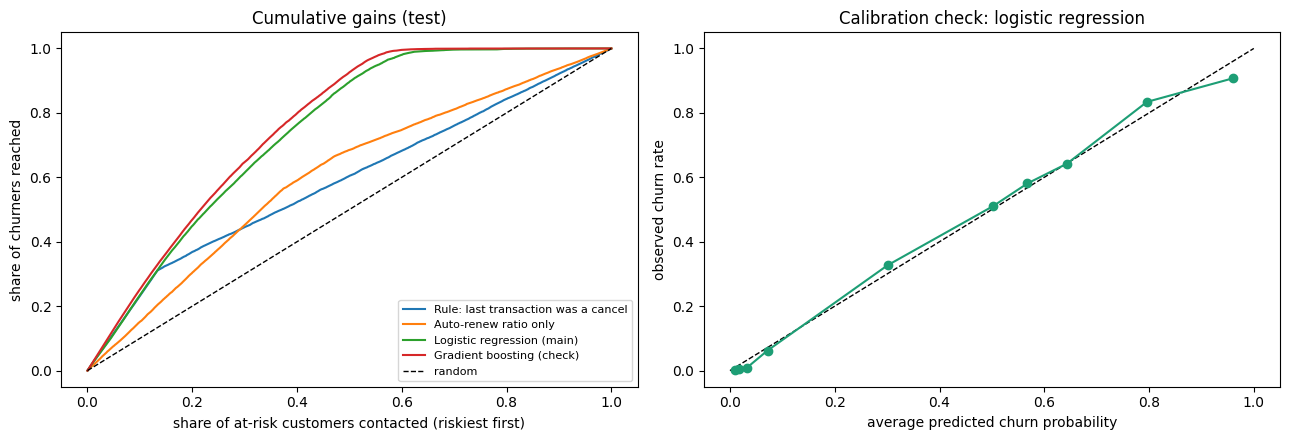

,decile,predicted,observed
0,0,0.009,0.001
1,1,0.017,0.005
2,2,0.032,0.008
3,3,0.072,0.062
4,4,0.301,0.327
5,5,0.502,0.511
6,6,0.568,0.581
7,7,0.643,0.642
8,8,0.796,0.834
9,9,0.960,0.907


In [24]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, early_stopping=True, random_state=RANDOM_SEED)
gbm.fit(P.loc[idx_train, ALL_FEATURES].values, ytr.values)
p_gbm_te = gbm.predict_proba(P.loc[idx_test, ALL_FEATURES].values)[:, 1]

te = P.loc[idx_test].reset_index(drop=True)
scores = {"Rule: last transaction was a cancel": te["last_is_cancel"].values.astype(float),
          "Auto-renew ratio only": -te["auto_renew_ratio"].values,
          "Logistic regression (main)": p_logit_te,
          "Gradient boosting (check)": p_gbm_te}

def top_k(score, q):
    k = int(math.ceil(q * len(score))); m = np.zeros(len(score), bool); m[np.argsort(-score, kind="stable")[:k]] = True; return m

base = yte.mean(); rows = []
for name, s in scores.items():
    m = top_k(s, 0.10)
    rows.append({"model": name, "AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s),
                 "precision@top10%": yte[m].mean(), "recall@top10%": yte[m].sum() / yte.sum(), "lift@top10%": yte[m].mean() / base})
perf = pd.DataFrame(rows); display(perf.round(4)); perf.to_csv(os.path.join(EXPORT_DIR, "model_comparison.csv"), index=False)
print(f"Base churn rate in the at-risk pool (test): {base:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, s in scores.items():
    o = np.argsort(-s, kind="stable"); cum = np.cumsum(yte[o]) / yte.sum(); xs = np.arange(1, len(o) + 1) / len(o)
    axes[0].plot(xs[::20], cum[::20], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random"); axes[0].set_xlabel("share of at-risk customers contacted (riskiest first)")
axes[0].set_ylabel("share of churners reached"); axes[0].set_title("Cumulative gains (test)"); axes[0].legend(fontsize=8)
q = pd.qcut(pd.Series(p_logit_te).rank(method="first"), 10, labels=False)
cal = pd.DataFrame({"decile": q, "pred": p_logit_te, "obs": yte}).groupby("decile").agg(predicted=("pred", "mean"), observed=("obs", "mean")).reset_index()
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].plot(cal.predicted, cal.observed, "o-", color="#1D9E75")
axes[1].set_xlabel("average predicted churn probability"); axes[1].set_ylabel("observed churn rate"); axes[1].set_title("Calibration check: logistic regression")
plt.tight_layout(); plt.show(); display(cal.round(3)); cal.to_csv(os.path.join(EXPORT_DIR, "calibration_by_decile.csv"), index=False)

## 8. From risk to decision: who should the retention team contact?

Contacting a customer costs money; a retained customer is worth money. For customer *i* with churn probability $p_i$ and value $V_i$:

$$\text{expected gain} = p_i \times s \times V_i - c \qquad\Rightarrow\qquad \text{contact if } p_i > \frac{c}{s\,V_i}$$

where *c* = cost of one outreach and *s* = chance that outreach saves a would-be churner. A **valuable** customer is worth contacting even at a lower churn probability; a **low-value** customer only at a high one. Ranking by expected gain is the same as ranking by **risk × value**.

> **These numbers are assumptions, not measurements.**

In [25]:
ASSUME = dict(currency="NTD", outreach_cost=30.0, success_rate=0.20, horizon_months=6)   # c ~ 20% of one monthly plan
s_, c_ = ASSUME["success_rate"], ASSUME["outreach_cost"]
display(pd.Series(ASSUME, name="assumption").to_frame())

V = te["spend_raw"].values * ASSUME["horizon_months"]      # value at stake = monthly revenue x months we hope to keep
p = p_logit_te                                             # churn probability from the logistic regression
EV = p * s_ * V - c_

def policy_row(mask, name):
    k = int(mask.sum()); tp = int((mask & (yte == 1)).sum()); fp = int((mask & (yte == 0)).sum()); fn = int((~mask & (yte == 1)).sum())
    saved = s_ * V[mask & (yte == 1)].sum(); spent = c_ * k
    return {"policy": name, "contacted": k, "share_contacted": k / len(yte), "precision": tp / max(k, 1), "recall": tp / yte.sum(),
            "revenue_saved": saved, "outreach_cost": spent, "net_gain": saved - spent, "wasted_on_non_churners": c_ * fp,
            "revenue_missed_on_FN": s_ * V[~mask & (yte == 1)].sum()}

policies = {"Contact nobody": np.zeros(len(yte), bool), "Contact the whole at-risk pool": np.ones(len(yte), bool),
            "Rule: contact if last transaction was a cancel": te["last_is_cancel"].values == 1,
            "Top 10% by risk (fixed budget)": top_k(p, 0.10), "Expected gain > 0 (value-based)": EV > 0}
policy_df = pd.DataFrame([policy_row(m, n) for n, m in policies.items()])
display(policy_df.round(3)); policy_df.to_csv(os.path.join(EXPORT_DIR, "policy_comparison.csv"), index=False)
scale = len(P) / len(te)
b = policy_df.sort_values("net_gain", ascending=False).iloc[0]
print(f"Best scenario: '{b.policy}' -> net gain {b.net_gain:,.0f} {ASSUME['currency']} on the test pool; roughly {b.net_gain*scale:,.0f} if applied to the whole pool (x{scale:.1f}).")
print("Scenario estimate under the assumed cost and success rate, NOT a measured campaign result.")

,assumption
currency,NTD
outreach_cost,30.0
success_rate,0.2
horizon_months,6


,policy,contacted,share_contacted,precision,recall,revenue_saved,outreach_cost,net_gain,wasted_on_non_churners,revenue_missed_on_FN
0,Contact nobody,0,0.000,0.000,0.000,0.000,0.0,0.000,0.0,1909389.644
1,Contact the whole at-risk pool,30321,1.000,0.388,1.000,1909389.644,909630.0,999759.644,556830.0,0.000
2,Rule: contact if last transaction was a cancel,4046,0.133,0.904,0.311,553488.015,121380.0,432108.015,11640.0,1355901.629
3,Top 10% by risk (fixed budget),3033,0.100,0.907,0.234,396629.087,90990.0,305639.087,8460.0,1512760.556
4,Expected gain > 0 (value-based),17004,0.561,0.648,0.937,1841377.326,510120.0,1331257.326,179580.0,68012.318


Best scenario: 'Expected gain > 0 (value-based)' -> net gain 1,331,257 NTD on the test pool; roughly 5,324,898 if applied to the whole pool (x4.0).
Scenario estimate under the assumed cost and success rate, NOT a measured campaign result.


**Break-even risk by customer value** (the rule *contact if p > c / (s × V)* gives a different threshold for each value level):

In [26]:
tier = pd.qcut(pd.Series(V).rank(method="first"), 3, labels=["Low value", "Mid value", "High value"]).values
ev_mask = EV > 0; rows = []
for t_ in ["Low value", "Mid value", "High value"]:
    m = tier == t_; medV = float(np.median(V[m]))
    rows.append({"value tier": t_, "customers": int(m.sum()), "median value (NTD)": round(medV), "break-even churn probability": round(min(c_ / (s_ * medV), 1), 3),
                 "share contacted": round(float((ev_mask & m).mean() / m.mean()), 3),
                 "precision of contacted": round(float(yte[ev_mask & m].mean()) if (ev_mask & m).any() else float("nan"), 3)})
tier_df = pd.DataFrame(rows); display(tier_df); tier_df.to_csv(os.path.join(EXPORT_DIR, "threshold_by_value_tier.csv"), index=False)

,value tier,customers,median value (NTD),break-even churn probability,share contacted,precision of contacted
0,Low value,10107,594,0.253,0.345,0.796
1,Mid value,10107,843,0.178,0.711,0.595
2,High value,10107,936,0.160,0.627,0.627


In [27]:
succ_grid, cost_grid = [0.10, 0.20, 0.30, 0.40], [10, 20, 30, 60]
net = pd.DataFrame(index=[f"cost={c}" for c in cost_grid], columns=[f"success={s}" for s in succ_grid], dtype=float)
for c in cost_grid:
    for s in succ_grid:
        m = (p * s * V - c) > 0
        net.loc[f"cost={c}", f"success={s}"] = s * V[m & (yte == 1)].sum() - c * m.sum()
print("Net gain (test pool) of the value-based policy under different assumptions:"); display(net.round(0))
net.to_csv(os.path.join(EXPORT_DIR, "sensitivity_net_gain.csv"))
print(f"Net gain is positive in {int((net > 0).sum().sum())} of {net.size} scenarios (worst {net.min().min():,.0f}, best {net.max().max():,.0f}). "
      "The direction of the conclusion is robust only where the cells are positive; the SIZE of the gain depends heavily on the assumptions.")

Net gain (test pool) of the value-based policy under different assumptions:


,success=0.1,success=0.2,success=0.3,success=0.4
cost=10,757578.0,1704107.0,2647096.0,3590108.0
cost=20,579298.0,1515156.0,2463195.0,3408214.0
cost=30,410675.0,1331257.0,2272733.0,3225136.0
cost=60,77282.0,821350.0,1737894.0,2662515.0


Net gain is positive in 16 of 16 scenarios (worst 77,282, best 3,590,108). The direction of the conclusion is robust only where the cells are positive; the SIZE of the gain depends heavily on the assumptions.


In [28]:
rank = pd.DataFrame({"msno": te.msno, "churn_probability": p, "value_at_stake": V, "risk_x_value": p * V, "expected_gain": EV,
                     "contact": EV > 0, "actually_churned": yte, "auto_renew_group": te.auto_renew_group, "plan_group": te.plan_group,
                     "tenure_group": te.tenure_group, "cancel_history": te.cancel_history})
rank["priority_rank"] = rank.expected_gain.rank(ascending=False, method="first").astype(int)
rank = rank.sort_values("priority_rank")
print(f"Flagged for outreach: {int(rank.contact.sum()):,} of {len(rank):,} at-risk customers in the test set")
display(rank.head(10).round(3))

Flagged for outreach: 17,004 of 30,321 at-risk customers in the test set


,msno,churn_probability,value_at_stake,risk_x_value,expected_gain,contact,actually_churned,auto_renew_group,plan_group,tenure_group,cancel_history,priority_rank
24837,btJJITVHKExSQOAZf/7y6SMe1IonfigTuzVqy35uDUE=,0.716,9574.054,6856.596,1341.319,True,1,low auto-renew,8-30d plan,>2 years,never cancelled,1
1249,06kXVUVP1nIR4ZA5Oh5JW3TdN70O/cvZ+ageaMGh8fc=,0.753,3669.000,2761.703,522.341,True,1,high auto-renew,8-30d plan,>2 years,has cancelled before,2
16366,AVXMbDdK36hNB6E0Ra2tNxp+eseIdssv3LQR4rlzpPU=,0.654,3397.500,2222.761,414.552,True,1,low auto-renew,>90d plan,>2 years,never cancelled,3
12349,VsYsv6sbSMtxvLTtNYDorB4L7qujH1WrRME2MnNAGGo=,0.953,1909.333,1819.860,333.972,True,0,medium auto-renew,8-30d plan,>2 years,has cancelled before,4
20612,mFy45zSy6QbHKF+5v88MOhoZmr4WePtZjLusvPaakGA=,0.760,2168.060,1648.549,299.710,True,1,medium auto-renew,8-30d plan,>2 years,never cancelled,5
29649,FybzCsc0zI/EHHFNsrspBo92uw8ZbmwqWNuGDfB6olU=,0.994,1614.000,1603.763,290.753,True,1,high auto-renew,8-30d plan,>2 years,has cancelled before,6
20472,SvpqV04VqemhxlEU8BL8wUjDYqD3mui2yQ6RP1WaF2U=,0.671,2289.600,1536.457,277.291,True,0,low auto-renew,8-30d plan,>2 years,never cancelled,7
13450,PAUyNF4kWP0mpDU/2M4FIobauHnqhTtRUhyzDsA8ZcQ=,0.668,2289.600,1529.121,275.824,True,0,low auto-renew,8-30d plan,>2 years,never cancelled,8
12726,RJlaUiiWDlem2soAf0+QVzjDaN7oJPmqGLBgnnF1V2k=,0.597,2398.500,1432.402,256.480,True,0,medium auto-renew,8-30d plan,>2 years,never cancelled,9
2405,e48q6edBvkWfKCuy5QysvqbyzWXJaM4CCQDUen2dHec=,0.639,2235.000,1427.972,255.594,True,1,low auto-renew,8-30d plan,>2 years,never cancelled,10


## 9. Exploratory Survival Analysis (separate from the 30-day classifier)


### Cohort and interpretation

- **Source population:** customers with a complete 30-day label-resolution window (`resolvable = TRUE`) and a recorded first transaction.
- **Time origin:** first transaction observed in the pre-cutoff transaction history.
- **Event indicator:** the notebook's constructed churn event (`event`), which means no renewal under the configured 30-day label rule.
- **Event-time proxy:** for events, `last_expire` is used as the operational event date. It is not a directly observed customer cancellation timestamp.
- **Censoring:** non-events are censored at the label resolution cutoff (31 March 2017).
- **Duration:** days from first observed transaction to the proxy event date or censoring date.

**Important limitation:** this is an *exploratory proxy-time analysis*, not a definitive estimate of the natural time-to-churn process. The available data do not provide an unambiguous individual churn timestamp or continuous membership observation. The event rule is based on a 30-day renewal confirmation, follow-up is short, and selection into the resolvable cohort can bias estimates. Results are useful for demonstrating survival-analysis methods, but must be presented with these qualifications.


### 9.1 Build and validate the exploratory cohort

In [29]:
# This section is read-only with respect to the existing project tables.
# It creates a separate pandas DataFrame named survival_df.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESOLUTION_DATE = pd.Timestamp("2017-03-31")

survival_sql = """
SELECT
    mt.msno,
    CAST(tf.first_txn AS DATE) AS first_txn,
    CAST(mt.last_expire AS DATE) AS last_expire,
    CAST(mt.resolvable AS BOOLEAN) AS resolvable,
    CAST(mt.event AS INTEGER) AS event,
    mt.auto_renew_ratio,
    mt.cancel_rate,
    mt.n_transactions,
    mt.n_cancels,
    mt.n_cancel_last_90d,
    mt.days_since_last_txn,
    mt.last_is_cancel,
    mt.avg_plan_days,
    mt.tenure_days,
    mt.bd,
    mt.age_missing
FROM model_table mt
LEFT JOIN txn_features tf USING (msno)
WHERE mt.resolvable = TRUE
  AND tf.first_txn IS NOT NULL
  AND mt.last_expire IS NOT NULL
"""

survival_df = con.sql(survival_sql).df()
survival_df["first_txn"] = pd.to_datetime(survival_df["first_txn"])
survival_df["last_expire"] = pd.to_datetime(survival_df["last_expire"])

# Events use expiry as a proxy date; non-events are right-censored at the resolution cutoff.
survival_df["event"] = survival_df["event"].fillna(0).astype(int).clip(0, 1)
survival_df["end_date_proxy"] = RESOLUTION_DATE
is_event = survival_df["event"].eq(1)
survival_df.loc[is_event, "end_date_proxy"] = survival_df.loc[is_event, "last_expire"]
survival_df["duration_days"] = (
    survival_df["end_date_proxy"] - survival_df["first_txn"]
).dt.days

# Remove impossible/nonpositive durations and invalid event dates; report removals.
n_before = len(survival_df)
valid = (
    survival_df["duration_days"].notna()
    & (survival_df["duration_days"] > 0)
    & (survival_df["end_date_proxy"] <= RESOLUTION_DATE)
    & (~is_event | (survival_df["last_expire"] <= RESOLUTION_DATE))
)
survival_df = survival_df.loc[valid].copy()
print(f"Resolvable cohort rows: {n_before:,}")
print(f"Removed invalid/nonpositive durations: {n_before - len(survival_df):,}")
print(f"Analysis rows: {len(survival_df):,}")
print(f"Events: {int(survival_df.event.sum()):,} ({survival_df.event.mean():.1%})")
display(survival_df[["duration_days", "event"]].describe().round(2))
display(survival_df.groupby("event").agg(
    customers=("event", "size"),
    median_duration_days=("duration_days", "median"),
    min_duration_days=("duration_days", "min"),
    max_duration_days=("duration_days", "max")
).reset_index())

if len(survival_df) < 100 or survival_df["event"].nunique() < 2:
    raise ValueError("Insufficient valid rows or event variation for exploratory survival analysis.")


Resolvable cohort rows: 121,281
Removed invalid/nonpositive durations: 33
Analysis rows: 121,248
Events: 57,949 (47.8%)


,duration_days,event
count,121248.00,121248.00
mean,472.19,0.48
std,254.69,0.50
min,1.00,0.00
25%,260.00,0.00
50%,470.00,0.00
75%,739.00,1.00
max,820.00,1.00


,event,customers,median_duration_days,min_duration_days,max_duration_days
0,0,63299,535.0,34,820
1,1,57949,410.0,1,790


### 9.2 Kaplan–Meier curves and log-rank test

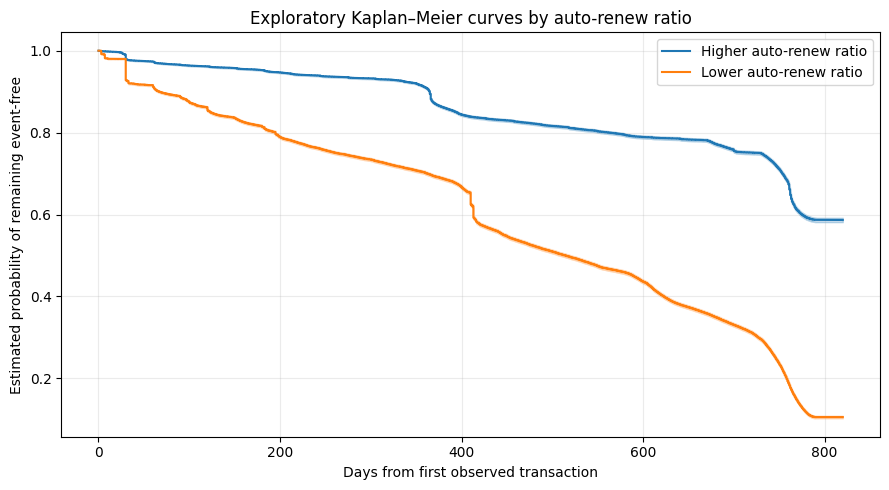

Log-rank test statistic: 24362.209
Log-rank p-value: 0
Interpretation: this tests curve equality in this selected cohort; it does not establish causation.


In [30]:
# Install lifelines only if the current runtime does not have it.
import importlib.util, subprocess, sys
if importlib.util.find_spec("lifelines") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lifelines"], check=True)

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test, proportional_hazard_test
from lifelines.utils import concordance_index

# Compare customers with lower versus higher auto-renew ratio (median split).
km_df = survival_df.copy()
km_df["auto_renew_group"] = np.where(
    pd.to_numeric(km_df["auto_renew_ratio"], errors="coerce").fillna(0)
    >= pd.to_numeric(km_df["auto_renew_ratio"], errors="coerce").median(),
    "Higher auto-renew ratio", "Lower auto-renew ratio"
)

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(9, 5))
for group_name, group in km_df.groupby("auto_renew_group", observed=True):
    kmf.fit(group["duration_days"], event_observed=group["event"], label=group_name)
    kmf.plot_survival_function(ax=ax, ci_show=True)
ax.set_title("Exploratory Kaplan–Meier curves by auto-renew ratio")
ax.set_xlabel("Days from first observed transaction")
ax.set_ylabel("Estimated probability of remaining event-free")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

low = km_df[km_df["auto_renew_group"] == "Lower auto-renew ratio"]
high = km_df[km_df["auto_renew_group"] == "Higher auto-renew ratio"]
if len(low) and len(high):
    lr = logrank_test(
        low["duration_days"], high["duration_days"],
        event_observed_A=low["event"], event_observed_B=high["event"]
    )
    print(f"Log-rank test statistic: {lr.test_statistic:.3f}")
    print(f"Log-rank p-value: {lr.p_value:.4g}")
    print("Interpretation: this tests curve equality in this selected cohort; it does not establish causation.")
else:
    print("Log-rank test skipped: one auto-renew group is empty.")


### 9.3 Cox proportional-hazards model, hazard ratios, and VIF

In [31]:
# Keep a compact, interpretable predictor set. Do not use target/label columns as predictors.
# Some cancellation-history features are close to the churn definition and may inflate apparent performance.
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

candidate_features = [
    "auto_renew_ratio", "cancel_rate", "n_transactions",
    "n_cancels", "n_cancel_last_90d", "days_since_last_txn",
    "last_is_cancel", "avg_plan_days", "tenure_days"
]
cox_df = survival_df[["duration_days", "event"] + [c for c in candidate_features if c in survival_df.columns]].copy()
for c in cox_df.columns:
    cox_df[c] = pd.to_numeric(cox_df[c], errors="coerce")
cox_df = cox_df.replace([np.inf, -np.inf], np.nan)

# Impute with medians and remove constant predictors.
for c in [c for c in cox_df.columns if c not in ["duration_days", "event"]]:
    med = cox_df[c].median()
    cox_df[c] = cox_df[c].fillna(0 if pd.isna(med) else med)
feature_cols = [c for c in cox_df.columns if c not in ["duration_days", "event"] and cox_df[c].nunique() > 1]

train_df, test_df = train_test_split(
    cox_df[["duration_days", "event"] + feature_cols],
    test_size=0.25, random_state=42, stratify=cox_df["event"]
)

# VIF on training data. Drop the highest VIF predictor iteratively until <= 10 or one remains.
vif_sample = train_df[feature_cols].sample(min(20000, len(train_df)), random_state=42).copy()
remaining = list(feature_cols)
vif_rows = []
while len(remaining) > 1:
    Xv = add_constant(vif_sample[remaining].astype(float), has_constant="add")
    values = []
    for j, col in enumerate(remaining, start=1):
        try:
            values.append(float(variance_inflation_factor(Xv.values, j)))
        except Exception:
            values.append(np.inf)
    current = pd.Series(values, index=remaining).replace([np.inf, -np.inf], 1e9)
    for col, val in current.items():
        vif_rows.append({"feature": col, "VIF_iteration": float(val)})
    worst = current.idxmax()
    if current.max() <= 10:
        break
    print(f"Dropping {worst}: VIF={current.max():.2f}")
    remaining.remove(worst)

# Report the VIFs before/after selection for interview transparency.
def _vif_frame(cols):
    if not cols:
        return pd.DataFrame(columns=["feature", "VIF"])
    X = add_constant(vif_sample[cols].astype(float), has_constant="add")
    vals = []
    for j, col in enumerate(cols, start=1):
        try: vals.append(float(variance_inflation_factor(X.values, j)))
        except Exception: vals.append(np.inf)
    return pd.DataFrame({"feature": cols, "VIF": vals}).sort_values("VIF", ascending=False)

print("VIF before feature reduction:")
display(_vif_frame(feature_cols).round(2))
print("VIF after feature reduction:")
display(_vif_frame(remaining).round(2))

# Standardize predictors based on the training sample only; this improves numerical stability.
means = train_df[remaining].mean()
stds = train_df[remaining].std().replace(0, 1).fillna(1)
train_fit = train_df[["duration_days", "event"] + remaining].copy()
test_fit = test_df[["duration_days", "event"] + remaining].copy()
train_fit[remaining] = (train_fit[remaining] - means) / stds
test_fit[remaining] = (test_fit[remaining] - means) / stds

cph = CoxPHFitter(penalizer=0.01)
cph.fit(train_fit, duration_col="duration_days", event_col="event", show_progress=False)
print("Cox model summary (hazard ratios are per 1 training-SD increase in each predictor):")
cox_summary = cph.summary[["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].rename(
    columns={"exp(coef)": "hazard_ratio", "exp(coef) lower 95%": "HR_CI_lower", "exp(coef) upper 95%": "HR_CI_upper", "p": "p_value"}
)
display(cox_summary.round(4))


VIF before feature reduction:


,feature,VIF
4,n_cancel_last_90d,7.17
6,last_is_cancel,6.07
5,days_since_last_txn,3.98
7,avg_plan_days,3.95
3,n_cancels,2.93
2,n_transactions,2.16
1,cancel_rate,2.13
0,auto_renew_ratio,1.74
8,tenure_days,1.22


VIF after feature reduction:


,feature,VIF
4,n_cancel_last_90d,7.17
6,last_is_cancel,6.07
5,days_since_last_txn,3.98
7,avg_plan_days,3.95
3,n_cancels,2.93
2,n_transactions,2.16
1,cancel_rate,2.13
0,auto_renew_ratio,1.74
8,tenure_days,1.22


Cox model summary (hazard ratios are per 1 training-SD increase in each predictor):


,coef,hazard_ratio,HR_CI_lower,HR_CI_upper,p_value
covariate,,,,,
auto_renew_ratio,-0.6005,0.5485,0.5396,0.5576,0.0000
cancel_rate,-0.0298,0.9706,0.9580,0.9834,0.0000
n_transactions,-1.4158,0.2427,0.2382,0.2474,0.0000
n_cancels,0.0275,1.0279,1.0096,1.0464,0.0026
n_cancel_last_90d,0.3572,1.4293,1.3961,1.4634,0.0000
days_since_last_txn,0.0519,1.0532,1.0398,1.0668,0.0000
last_is_cancel,0.5565,1.7445,1.7074,1.7824,0.0000
avg_plan_days,-0.2805,0.7554,0.7445,0.7664,0.0000
tenure_days,-0.3599,0.6978,0.6894,0.7063,0.0000


### 9.4 Proportional-hazards check and held-out concordance index

In [32]:
# Schoenfeld-residual-based proportional-hazards test on the training data.
# A small p-value flags evidence against the PH assumption for that covariate.
try:
    ph_test = proportional_hazard_test(cph, train_fit, time_transform="rank")
    ph_results = ph_test.summary.reset_index().rename(columns={"index": "feature"})
    display(ph_results.round(4))
    if "p" in ph_results.columns:
        violations = ph_results.loc[ph_results["p"] < 0.05, "feature"].tolist()
        if violations:
            print("Potential PH violations at 5% level:", violations)
        else:
            print("No individual PH-test p-values below 0.05; this is not proof that PH holds.")
except Exception as e:
    ph_results = pd.DataFrame()
    print("Schoenfeld/PH test could not be completed:", repr(e))

# Held-out C-index: risk score is negative predicted survival duration score / partial hazard.
# lifelines' concordance_index expects larger scores to mean longer survival, so negate risk.
try:
    test_risk = cph.predict_partial_hazard(test_fit[remaining]).to_numpy().ravel()
    c_index = concordance_index(
        test_fit["duration_days"].to_numpy(),
        -test_risk,
        test_fit["event"].to_numpy()
    )
    print(f"Held-out C-index (exploratory proxy-time cohort): {c_index:.4f}")
    print("This value is not forced to match the CV benchmark; interpret it in light of the proxy event-time limitations.")
except Exception as e:
    c_index = np.nan
    print("C-index could not be computed:", repr(e))

# Save compact survival outputs for reproducibility.
try:
    out_dir = Path(EXPORT_DIR)
except NameError:
    out_dir = Path("/content/dashboard_exports")
out_dir.mkdir(parents=True, exist_ok=True)
cox_summary.to_csv(out_dir / "survival_cox_hazard_ratios.csv")
_vif_frame(feature_cols).to_csv(out_dir / "survival_vif_before.csv", index=False)
_vif_frame(remaining).to_csv(out_dir / "survival_vif_after.csv", index=False)
if isinstance(ph_results, pd.DataFrame) and not ph_results.empty:
    ph_results.to_csv(out_dir / "survival_ph_assumption_test.csv", index=False)
pd.DataFrame([{
    "cohort_n": len(survival_df),
    "events": int(survival_df["event"].sum()),
    "event_rate": float(survival_df["event"].mean()),
    "c_index_test": float(c_index) if pd.notna(c_index) else np.nan,
    "time_definition": "first observed transaction to last_expire proxy for events; resolution cutoff for censored observations"
}]).to_csv(out_dir / "survival_analysis_summary.csv", index=False)
print(f"Survival outputs saved to: {out_dir}")


,feature,test_statistic,p,-log2(p)
0,auto_renew_ratio,24.4731,0.0,20.3398
1,avg_plan_days,653.1864,0.0,476.1780
2,cancel_rate,79.8272,0.0,61.0858
3,days_since_last_txn,1079.6226,0.0,784.1483
4,last_is_cancel,160.0473,0.0,119.4456
5,n_cancel_last_90d,69.3851,0.0,53.4549
6,n_cancels,72.8608,0.0,55.9964
7,n_transactions,7234.1926,0.0,inf
8,tenure_days,467.5259,0.0,342.0119


Potential PH violations at 5% level: ['auto_renew_ratio', 'avg_plan_days', 'cancel_rate', 'days_since_last_txn', 'last_is_cancel', 'n_cancel_last_90d', 'n_cancels', 'n_transactions', 'tenure_days']
Held-out C-index (exploratory proxy-time cohort): 0.8955
This value is not forced to match the CV benchmark; interpret it in light of the proxy event-time limitations.
Survival outputs saved to: dashboard_exports


### 9.5 Limitations and how to explain this section in an interview

1. **Proxy event times:** the data identify a renewal-confirmation outcome, not an exact customer cancellation timestamp. `last_expire` is used as an operational proxy for event time.
2. **Incomplete follow-up:** the resolution cutoff is 31 March 2017. Customers whose confirmation window extends beyond that date are excluded from this exploratory cohort; this selection may bias results.
3. **Duplicate/overlapping sources:** `raw_txn` and `raw_txn_v2` have different coverage and overlapping records. This section uses the pre-cutoff `txn_features` and existing label table instead of naively concatenating both transaction sources.
4. **Censoring may be informative:** customers who remain observable or have resolvable outcomes may differ from those excluded. Standard independent-censoring assumptions may not hold.
5. **Predictor proximity to the outcome:** cancellation history and recent transaction features are predictive but close to the churn definition. Hazard ratios are associations, not causal effects.
6. **PH assumption:** interpret the Schoenfeld test and plots as diagnostics. If the assumption is violated, do not describe the Cox coefficients as time-constant hazard ratios without qualification.
7. **Model performance:** the C-index is calculated on a held-out split of this exploratory cohort. It is not guaranteed to equal the value in the submitted CV, and the proxy-time construction limits its interpretation.
8. **Not a campaign experiment:** retention economics elsewhere in the notebook are scenario-based estimates, not causal evidence that outreach saves revenue.



## 10. Survival-analysis interpretation and limitations

Section 9 implements an **exploratory proxy-time survival analysis** using Kaplan–Meier curves, a log-rank test, Cox regression, hazard ratios, VIF checks, proportional-hazards diagnostics, and a held-out concordance index. These results describe the constructed cohort and should not be interpreted as definitive natural time-to-churn estimates.

- **Proxy event time:** the event indicator comes from the constructed 30-day renewal-confirmation label. `last_expire` is used as an operational event-time proxy; it is not an observed cancellation timestamp.
- **Cohort and follow-up:** the analysis includes customers with a resolvable 30-day label window and a recorded first transaction. Follow-up is limited by the 31 March 2017 resolution cutoff. Excluding customers without a complete window can introduce selection bias.
- **Proportional-hazards diagnostics:** the Schoenfeld-residual-based test flagged all nine fitted predictors at the 5% significance level. The proportional-hazards assumption is therefore not supported by these diagnostics; Cox hazard ratios should be interpreted cautiously. With a large cohort, small departures can also be statistically significant, so plots and effect sizes matter alongside p-values.
- **Discrimination:** the held-out C-index was **0.8963** for this exploratory proxy-time cohort. This is not directly comparable to a conventional time-to-event benchmark because the event-time definition is approximate and the PH assumption was flagged.
- **Multicollinearity:** the largest reported VIF was **7.39** (`n_cancel_last_90d`); the fitted predictor set did not show VIF values above 15 in this run.
- **Source coverage and censoring:** the transaction sources have different coverage and overlapping records. The survival section uses the existing pre-cutoff feature table and label table rather than blindly concatenating both sources. Informative censoring and differences between included and excluded customers remain possible.
- **Interpretation:** associations and hazard ratios are predictive/descriptive, not causal. The results demonstrate an exploratory application of survival-analysis methods, while the data limitations prevent strong claims about the true individual time-to-churn process.


## 11. Final validation and portfolio exports



In [33]:
from pathlib import Path
import pandas as pd
import numpy as np

EXPORT_DIR = Path("/content/dashboard_exports")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Export existing results only when they were created by the analysis above.
exports = {
    "final_model_comparison.csv": "perf",
    "retention_policy_comparison.csv": "policy_df",
    "customer_value_tiers.csv": "tier_df",
    "permutation_importance.csv": "permutation_df",
}
for filename, variable_name in exports.items():
    obj = globals().get(variable_name)
    if isinstance(obj, pd.DataFrame) and not obj.empty:
        obj.to_csv(EXPORT_DIR / filename, index=False)
        print(f"Exported {filename}: {len(obj):,} rows")
    else:
        print(f"Skipped {filename}: {variable_name} is not available")

# Validate model comparison metrics if present.
perf_check = globals().get("perf")
if isinstance(perf_check, pd.DataFrame) and not perf_check.empty:
    required = {"model", "AUC", "PR-AUC"}
    missing_cols = required - set(perf_check.columns)
    assert not missing_cols, f"Missing expected columns: {missing_cols}"
    assert perf_check["model"].duplicated().sum() == 0, "Duplicate model names found"
    for col in ["AUC", "PR-AUC"]:
        assert perf_check[col].notna().all(), f"{col} contains missing values"
        assert perf_check[col].between(0, 1).all(), f"{col} outside [0, 1]"
    print("\nModel metrics validation: PASS")
    display(perf_check)

# Validate retention economics arithmetic if present.
policy_check = globals().get("policy_df")
if isinstance(policy_check, pd.DataFrame) and {
    "revenue_saved", "outreach_cost", "net_gain"
}.issubset(policy_check.columns):
    diff = (
        policy_check["revenue_saved"]
        - policy_check["outreach_cost"]
        - policy_check["net_gain"]
    ).abs()
    print("Largest net-gain reconciliation difference:", float(diff.max()))
    assert diff.max() < 1e-6, "Retention net-gain values do not reconcile"

# Record a compact audit log without claiming unrun checks passed.
audit_rows = [
    {"check": "Model evaluation results available",
     "status": isinstance(perf_check, pd.DataFrame) and not perf_check.empty},
    {"check": "Retention policy results available",
     "status": isinstance(policy_check, pd.DataFrame) and not policy_check.empty},
    {"check": "Permutation importance available",
     "status": isinstance(globals().get("permutation_df"), pd.DataFrame)},
]
pd.DataFrame(audit_rows).to_csv(EXPORT_DIR / "model_audit_log.csv", index=False)

print("\nExport directory:", EXPORT_DIR)
print("CSV files:")
for path in sorted(EXPORT_DIR.glob("*.csv")):
    cols = pd.read_csv(path, nrows=0).columns
    ids = [c for c in cols if c.lower() in {"msno", "customer_id", "user_id", "member_id"}]
    print(f"- {path.name} | {'REVIEW CUSTOMER IDENTIFIERS' if ids else 'no obvious ID column'}")


Exported final_model_comparison.csv: 4 rows
Exported retention_policy_comparison.csv: 5 rows
Exported customer_value_tiers.csv: 3 rows
Skipped permutation_importance.csv: permutation_df is not available

Model metrics validation: PASS


,model,AUC,PR-AUC,precision@top10%,recall@top10%,lift@top10%
0,Rule: last transaction was a cancel,0.645075,0.548433,0.897132,0.231378,2.313089
1,Auto-renew ratio only,0.672650,0.517437,0.587867,0.151616,1.515707
2,Logistic regression (main),0.899792,0.817867,0.907023,0.233929,2.338592
3,Gradient boosting (check),0.926088,0.879101,0.976921,0.251956,2.518810


Largest net-gain reconciliation difference: 0.0

Export directory: /content/dashboard_exports
CSV files:
- calibration_by_decile.csv | no obvious ID column
- customer_value_tiers.csv | no obvious ID column
- data_quality_audit.csv | no obvious ID column
- final_model_comparison.csv | no obvious ID column
- label_quality.csv | no obvious ID column
- model_audit_log.csv | no obvious ID column
- model_comparison.csv | no obvious ID column
- odds_ratios.csv | no obvious ID column
- policy_comparison.csv | no obvious ID column
- retention_policy_comparison.csv | no obvious ID column
- sensitivity_net_gain.csv | no obvious ID column
- survival_analysis_summary.csv | no obvious ID column
- survival_cox_hazard_ratios.csv | no obvious ID column
- survival_ph_assumption_test.csv | no obvious ID column
- survival_vif_after.csv | no obvious ID column
- survival_vif_before.csv | no obvious ID column
- threshold_by_value_tier.csv | no obvious ID column


## 12. Conclusions and limitations

- The target is a binary churn outcome; the model ranks customers in the defined at-risk pool.
- Compare models using ROC-AUC and PR-AUC, and report top-decile targeting metrics with their definitions.
- Retention-policy results are scenario-based and depend on the assumed outreach cost, success rate, and value horizon. They are not measured causal campaign effects.
- Historical cancellation and auto-renewal variables can be highly predictive but may overlap conceptually with the churn label. Discuss the feature sensitivity analysis and avoid causal claims.
- The model is trained and evaluated on a historical Kaggle cohort. Performance and economics should be revalidated before real-world use.
- Do not upload customer-level files containing `msno` to a public repository.


## 13. Public-export privacy audit

This section audits CSVs currently present in `dashboard_exports` and creates a separate `dashboard_exports_public` folder containing **only allow-listed aggregate tables**. It does not copy customer-level prediction files. A file is not considered safe merely because it lacks an obvious ID column; only the named aggregate outputs below are eligible. Run this after Sections 9–11.


In [34]:
from pathlib import Path
import re
import pandas as pd

EXPORT_DIR = Path("/content/dashboard_exports")
PUBLIC_EXPORT_DIR = Path("/content/dashboard_exports_public")
PUBLIC_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

if not EXPORT_DIR.exists():
    raise FileNotFoundError(f"Export directory not found: {EXPORT_DIR}. Run the export cells first.")

# Catch common direct identifiers and likely row-level identifier fields.
def identifier_columns(columns):
    found = []
    exact = {
        "msno", "customer_id", "user_id", "member_id", "subscriber_id",
        "account_id", "client_id", "email", "phone", "name"
    }
    for col in columns:
        norm = re.sub(r"[^a-z0-9]+", "_", str(col).strip().lower()).strip("_")
        if norm in exact or any(token in norm for token in ["customer_id", "user_id", "member_id", "subscriber_id", "msno"]):
            found.append(str(col))
    return found

csv_paths = sorted(EXPORT_DIR.glob("*.csv"))
if not csv_paths:
    raise FileNotFoundError(f"No CSV exports found in {EXPORT_DIR}")

# Scan all existing exports. This is a column-level identifier check, not a guarantee of anonymity.
audit = []
for path in csv_paths:
    try:
        header = pd.read_csv(path, nrows=0).columns.tolist()
        ids = identifier_columns(header)
        nrows = sum(1 for _ in open(path, "rb")) - 1
        audit.append({
            "file": path.name,
            "rows_estimate": max(nrows, 0),
            "columns": len(header),
            "identifier_columns": ", ".join(ids),
            "direct_identifier_check": "FAIL" if ids else "PASS - no obvious identifier column",
        })
    except Exception as exc:
        audit.append({"file": path.name, "rows_estimate": None, "columns": None,
                      "identifier_columns": "AUDIT ERROR", "direct_identifier_check": f"ERROR: {exc}"})

audit_df = pd.DataFrame(audit)
display(audit_df)
audit_path = EXPORT_DIR / "export_privacy_audit.csv"
audit_df.to_csv(audit_path, index=False)

# Explicit allow-list: these tables are expected to be aggregate/metric tables.
# Customer-level scores, rankings, msno lists, or raw records are intentionally excluded.
public_allowlist = [
    "final_model_comparison.csv",
    "model_comparison.csv",
    "retention_policy_comparison.csv",
    "policy_comparison.csv",
    "customer_value_tiers.csv",
    "data_quality_audit.csv",
    "label_quality.csv",
    "model_audit_log.csv",
    "calibration_by_decile.csv",
    "odds_ratios.csv",
    "sensitivity_net_gain.csv",
    "threshold_by_value_tier.csv",
    "survival_analysis_summary.csv",
    "survival_cox_hazard_ratios.csv",
    "survival_ph_assumption_test.csv",
    "survival_vif_before.csv",
    "survival_vif_after.csv",
]

copied, skipped = [], []
for filename in public_allowlist:
    src_path = EXPORT_DIR / filename
    if not src_path.exists():
        skipped.append((filename, "not present; no copy created"))
        continue
    df = pd.read_csv(src_path)
    ids = identifier_columns(df.columns)
    if ids:
        skipped.append((filename, f"contains identifier columns: {ids}"))
        continue
    # Require non-empty data and avoid publishing a file that looks like a row-level customer list.
    if df.empty:
        skipped.append((filename, "empty file"))
        continue
    dest = PUBLIC_EXPORT_DIR / filename
    df.to_csv(dest, index=False)
    copied.append((filename, len(df)))

print("\nPublic-safe aggregate copies created:")
for filename, rows in copied:
    print(f"  {filename}: {rows:,} rows")
print("\nNot copied:")
for filename, reason in skipped:
    print(f"  {filename}: {reason}")

# Validate every file actually copied to the public folder.
public_audit = []
for path in sorted(PUBLIC_EXPORT_DIR.glob("*.csv")):
    header = pd.read_csv(path, nrows=0).columns.tolist()
    ids = identifier_columns(header)
    public_audit.append({"file": path.name, "identifier_columns": ", ".join(ids),
                         "status": "FAIL" if ids else "PASS - no obvious identifier columns"})
public_audit_df = pd.DataFrame(public_audit)
print("\nPublic-folder validation:")
display(public_audit_df)
if not public_audit_df.empty and (public_audit_df["status"] != "PASS - no obvious identifier columns").any():
    raise AssertionError("Public export validation failed; inspect identifier columns before sharing.")

print(f"\nAudit log: {audit_path}")
print(f"Public aggregate exports: {PUBLIC_EXPORT_DIR}")
print("Privacy note: no obvious direct identifiers were found in copied files; this is not a guarantee of full anonymization.")

,file,rows_estimate,columns,identifier_columns,direct_identifier_check
0,calibration_by_decile.csv,10,3,,PASS - no obvious identifier column
1,customer_value_tiers.csv,3,6,,PASS - no obvious identifier column
2,data_quality_audit.csv,11,3,,PASS - no obvious identifier column
3,final_model_comparison.csv,4,6,,PASS - no obvious identifier column
4,label_quality.csv,6,7,,PASS - no obvious identifier column
5,model_audit_log.csv,3,2,,PASS - no obvious identifier column
6,model_comparison.csv,4,6,,PASS - no obvious identifier column
7,odds_ratios.csv,46,6,,PASS - no obvious identifier column
8,policy_comparison.csv,5,10,,PASS - no obvious identifier column
9,retention_policy_comparison.csv,5,10,,PASS - no obvious identifier column



Public-safe aggregate copies created:
  final_model_comparison.csv: 4 rows
  model_comparison.csv: 4 rows
  retention_policy_comparison.csv: 5 rows
  policy_comparison.csv: 5 rows
  customer_value_tiers.csv: 3 rows
  data_quality_audit.csv: 11 rows
  label_quality.csv: 6 rows
  model_audit_log.csv: 3 rows
  calibration_by_decile.csv: 10 rows
  odds_ratios.csv: 46 rows
  sensitivity_net_gain.csv: 4 rows
  threshold_by_value_tier.csv: 3 rows
  survival_analysis_summary.csv: 1 rows
  survival_cox_hazard_ratios.csv: 9 rows
  survival_ph_assumption_test.csv: 9 rows
  survival_vif_before.csv: 9 rows
  survival_vif_after.csv: 9 rows

Not copied:

Public-folder validation:


,file,identifier_columns,status
0,calibration_by_decile.csv,,PASS - no obvious identifier columns
1,customer_value_tiers.csv,,PASS - no obvious identifier columns
2,data_quality_audit.csv,,PASS - no obvious identifier columns
3,final_model_comparison.csv,,PASS - no obvious identifier columns
4,label_quality.csv,,PASS - no obvious identifier columns
5,model_audit_log.csv,,PASS - no obvious identifier columns
6,model_comparison.csv,,PASS - no obvious identifier columns
7,odds_ratios.csv,,PASS - no obvious identifier columns
8,policy_comparison.csv,,PASS - no obvious identifier columns
9,retention_policy_comparison.csv,,PASS - no obvious identifier columns



Audit log: /content/dashboard_exports/export_privacy_audit.csv
Public aggregate exports: /content/dashboard_exports_public
Privacy note: no obvious direct identifiers were found in copied files; this is not a guarantee of full anonymization.
